# 환경 설정

## 한글화 코드

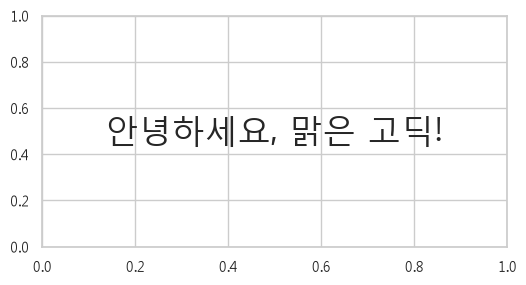

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

# seaborn 스타일을 먼저 적용
sns.set_theme(style="whitegrid")

# Windows 한글 글꼴 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 한글 표시 확인
plt.figure(figsize=(6, 3))
plt.text(
    0.5, 0.5,
    "안녕하세요, 맑은 고딕!",
    ha="center",
    va="center",
    size=24
)
plt.show()

## MySQL 연결

In [2]:
import pandas as pd
from getpass import getpass
from sqlalchemy import create_engine, URL, text

url = URL.create(
    drivername="mysql+pymysql",
    username="root",
    password=getpass("MySQL 비밀번호: "),
    host="localhost",
    port=3306,
    database="final",
    query={"charset": "utf8mb4"},
)

engine = create_engine(url, pool_pre_ping=True)

# 연결 확인
with engine.connect() as conn:
    print(conn.execute(text("SELECT VERSION()")).scalar())

8.0.37


In [3]:
query = "SELECT * FROM accounts_user LIMIT 5"

with engine.connect() as conn:
    df = pd.read_sql_query(text(query), conn)

df.head()

,id,is_superuser,is_staff,gender,point,friend_id_list,is_push_on,created_at,block_user_id_list,hide_user_id_list,ban_status,report_count,alarm_count,pending_chat,pending_votes,group_id
0,831956,1,1,None,600,"[1292473, 913158, 1488461, 1064695, 1043565, 1...",0,2023-03-29 03:44:14.047130,[],[],N,0,0,0,0,NaN
1,831962,0,0,F,2248,"[833025, 832642, 982531, 879496, 838541, 83752...",1,2023-03-29 05:18:56.162368,[],[],N,253,40878,5499,110,12.0
2,832151,0,0,M,1519,"[838785, 982531, 882567, 879496, 838541, 83649...",0,2023-03-29 12:56:34.989468,[],[],N,0,37,0,47,1.0
3,832340,0,0,F,57,"[841345, 982531, 838785, 963714, 882567, 83252...",1,2023-03-29 12:56:35.020790,[],[],N,0,19,0,21,1.0
4,832520,0,0,M,1039,"[874050, 849763, 874212, 844297, 838541, 84004...",0,2023-03-29 12:56:35.049311,[],[],N,0,29,0,15,12.0


## DataFrame에 저장

In [4]:
import pandas as pd
from sqlalchemy import text

params = {
    "start_at": "2023-05-04 00:00:00",
    "end_at": "2024-05-06 00:00:00",
}

queries = {
    "polls_question": """
        SELECT
            id,
            TRIM(question_text) AS question_text,
            created_at
        FROM final.polls_question
    """,

    "polls_questionreport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            question_id,
            user_id
        FROM final.polls_questionreport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_usercandidate": """
        SELECT
            id,
            created_at,
            question_piece_id,
            user_id
        FROM final.polls_usercandidate
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionset": """
        SELECT
            id,
            question_piece_id_list,
            opening_time,
            status,
            user_id
        FROM final.polls_questionset
        WHERE opening_time >= created_at
          AND status = 'F'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    "polls_questionpiece": """
        SELECT
            id,
            is_voted,
            question_id,
            is_skipped
        FROM final.polls_questionpiece
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_userquestionrecord": """
        SELECT
            id,
            status,
            created_at,
            chosen_user_id,
            question_id,
            user_id,
            question_piece_id,
            has_read,
            answer_status,
            answer_updated_at,
            report_count,
            opened_times
        FROM final.accounts_userquestionrecord
        WHERE answer_status <> 'P'
          AND created_at >= :start_at
          AND created_at < :end_at
    """,

    # 가입일 제한 없이 일반 유저 전체 조회
    "accounts_user": """
        SELECT
            id,
            is_superuser,
            is_staff,
            gender,
            friend_id_list,
            is_push_on,
            created_at,
            block_user_id_list,
            hide_user_id_list,
            ban_status,
            report_count,
            group_id
        FROM final.accounts_user
        WHERE is_superuser = 0
          AND is_staff = 0
    """,

    "accounts_timelinereport": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            reported_user_id,
            user_id,
            user_question_record_id
        FROM final.accounts_timelinereport
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    "accounts_school": """
        SELECT
            id,
            student_count,
            school_type
        FROM final.accounts_school
    """,

    "accounts_group": """
        SELECT
            id,
            school_id
        FROM final.accounts_group
    """,

    "accounts_blockrecord": """
        SELECT
            id,
            TRIM(reason) AS reason,
            created_at,
            block_user_id,
            user_id
        FROM final.accounts_blockrecord
        WHERE created_at >= :start_at
          AND created_at < :end_at
    """,

    # 생성일 컬럼이 없어 전체 조회
    "accounts_attendance": """
        SELECT
            id,
            attendance_date_list,
            user_id
        FROM final.accounts_attendance
    """,
}

dfs = {}

with engine.connect() as conn:
    for table_name, query in queries.items():
        dfs[table_name] = pd.read_sql_query(
            text(query),
            conn,
            params=params,
        )

        df = dfs[table_name]
        print(f"{table_name}: {len(df):,}행 × {len(df.columns)}열")

# 개별 DataFrame 변수
df_question = dfs["polls_question"]
df_questionreport = dfs["polls_questionreport"]
df_usercandidate = dfs["polls_usercandidate"]
df_questionset = dfs["polls_questionset"]
df_questionpiece = dfs["polls_questionpiece"]
df_userquestionrecord = dfs["accounts_userquestionrecord"]
df_user = dfs["accounts_user"]
df_timelinereport = dfs["accounts_timelinereport"]
df_school = dfs["accounts_school"]
df_group = dfs["accounts_group"]
df_blockrecord = dfs["accounts_blockrecord"]
df_attendance = dfs["accounts_attendance"]

polls_question: 5,025행 × 3열
polls_questionreport: 48,928행 × 5열
polls_usercandidate: 4,452,529행 × 4열
polls_questionset: 141,909행 × 5열
polls_questionpiece: 1,177,414행 × 4열
accounts_userquestionrecord: 1,128,249행 × 12열
accounts_user: 677,081행 × 12열
accounts_timelinereport: 208행 × 6열
accounts_school: 5,951행 × 3열
accounts_group: 84,515행 × 2열
accounts_blockrecord: 19,481행 × 5열
accounts_attendance: 349,637행 × 3열


In [5]:
query_attendance = """
SELECT
    id,
    attendance_date_list,
    user_id
FROM final.accounts_attendance
"""

with engine.connect() as conn:
    df_attendance = pd.read_sql_query(text(query_attendance), conn)

dfs["accounts_attendance"] = df_attendance

print(f"accounts_attendance: {len(df_attendance):,}행 × {len(df_attendance.columns)}열")

df_attendance.head()

accounts_attendance: 349,637행 × 3열


,id,attendance_date_list,user_id
0,1,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1446852
1,2,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1359398
2,3,"[""2023-05-27"", ""2023-05-29"", ""2023-05-30"", ""20...",1501542
3,4,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1507767
4,5,"[""2023-05-27"", ""2023-05-28"", ""2023-05-29"", ""20...",1287453


# 전처리

## 중복값 확인

In [6]:
duplicate_results = []

for table_name, df in dfs.items():
    duplicate_results.append({
        "테이블": table_name,
        "전체 행 수": len(df),

        # 첫 행을 제외한 추가 중복 행 수
        "전체 컬럼 중복 행 수": int(df.duplicated().sum()),

        # 기본키 중복 및 누락
        "ID 중복 수": (
            int(df["id"].duplicated().sum())
            if "id" in df.columns else pd.NA
        ),
        "ID 결측 수": (
            int(df["id"].isna().sum())
            if "id" in df.columns else pd.NA
        ),
    })

df_duplicate_summary = pd.DataFrame(duplicate_results)

df_duplicate_summary

,테이블,전체 행 수,전체 컬럼 중복 행 수,ID 중복 수,ID 결측 수
0,polls_question,5025,0,0,0
1,polls_questionreport,48928,0,0,0
2,polls_usercandidate,4452529,0,0,0
3,polls_questionset,141909,0,0,0
4,polls_questionpiece,1177414,0,0,0
5,accounts_userquestionrecord,1128249,0,0,0
6,accounts_user,677081,0,0,0
7,accounts_timelinereport,208,0,0,0
8,accounts_school,5951,0,0,0
9,accounts_group,84515,0,0,0


# EDA

## 전체 질문 신고 순위 확인

### 질문 신고 순위

In [7]:
# 긍정적 사유 제외
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_question_report_top10 = (
    df_questionreport.loc[~positive_mask]
    .groupby("question_id")
    .agg(
        신고_수=("id", "size"),
        고유_신고자_수=("user_id", "nunique"),
    )
    .reset_index()
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "question_id",
            "question_text": "질문명",
        }),
        on="question_id",
        how="left",
        validate="one_to_one",
    )
    .rename(columns={
        "question_id": "질문 ID",
        "신고_수": "신고 수",
        "고유_신고자_수": "고유 신고자 수",
    })
    [["질문 ID", "질문명", "신고 수", "고유 신고자 수"]]
    .sort_values(
        ["신고 수", "고유 신고자 수", "질문 ID"],
        ascending=[False, False, True],
    )
    .head(10)
    .reset_index(drop=True)
)

df_question_report_top10

,질문 ID,질문명,신고 수,고유 신고자 수
0,111,마스크가 잘 어울리는 사람은?,891,693
1,410,발냄새가 호두과자 냄새일 것 같은 사람은?,791,678
2,398,등빨이 가장 좋은 사람은?,657,554
3,424,어깨가 가장 넓은 사람은?,531,458
4,305,먹방을 가장 잘할 것 같은 사람은?,475,392
5,564,설레면 콧구멍이 커지는 친구는?,338,309
6,144,발냄새가 가장 향긋할 것 같은 사람은?,284,246
7,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,281,243
8,494,먹방 찍으면 100만 유튜버가 될 것 같은 친구,256,209
9,479,치킨 중독인 것 같은 사람은?,235,196


### 질문 신고 사유 순위

In [8]:
# 긍정적 사유를 제외한 질문 신고 사유 순위
reasons = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .fillna("사유 미기재")
    .replace("", "사유 미기재")
)

df_question_report_reason_ranking = (
    reasons.loc[
        reasons.ne("어떻게 이런 생각을? 이 질문 최고!")
    ]
    .value_counts()
    .rename_axis("신고 사유")
    .reset_index(name="신고 수")
)

total_reports = df_question_report_reason_ranking["신고 수"].sum()

df_question_report_reason_ranking["비율(%)"] = (
    df_question_report_reason_ranking["신고 수"]
    / total_reports * 100
    if total_reports else float("nan")
)

df_question_report_reason_ranking.round(2)

,신고 사유,신고 수,비율(%)
0,그냥 싫어,28446,58.6
1,나랑 맞지 않는 질문인 것 같음,9541,19.65
2,불쾌한 질문 내용,5386,11.09
3,자꾸 같은 내용의 질문 반복,3202,6.6
4,한 친구가 질문을 반복적으로 보냄,1701,3.5
5,이 질문은 재미없어요,92,0.19
6,기타,85,0.18
7,불쾌한 내용이 포함되어 있음,72,0.15
8,오타가 있음,11,0.02
9,선정적이거나 자극적인 질문,9,0.02


## 학생들의 신고·차단 행동 패턴

### 성별에 따른 질문 신고 Top10

In [9]:
# 질문 신고에 신고자 성별·질문명 연결
df_gender_reports = (
    df_questionreport.loc[
        df_questionreport["reason"]
        .astype("string")
        .str.strip()
        .eq("불쾌한 질문 내용")
        .fillna(False)
    ]
    .merge(
        df_user[["id", "gender"]].rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(columns={
            "id": "question_id",
            "question_text": "질문명",
        }),
        on="question_id",
        how="left",
        validate="many_to_one",
    )
)

def get_gender_top10(gender, label):
    return (
        df_gender_reports.loc[
            df_gender_reports["gender"].eq(gender)
        ]
        .groupby(["question_id", "질문명"], dropna=False)
        .size()
        .reset_index(name=f"{label} 신고 수")
        .sort_values(
            [f"{label} 신고 수", "question_id"],
            ascending=[False, True],
        )
        .head(10)
        .rename(columns={
            "question_id": f"{label} 질문 ID",
            "질문명": f"{label} 질문명",
        })
        .reset_index(drop=True)
    )

df_gender_question_top10 = pd.concat(
    [
        get_gender_top10("F", "여학생"),
        get_gender_top10("M", "남학생"),
    ],
    axis=1,
)

print(
    "성별 확인 불가 신고:",
    f"{df_gender_reports['gender'].isna().sum():,}건",
)

df_gender_question_top10

성별 확인 불가 신고: 0건


,여학생 질문 ID,여학생 질문명,여학생 신고 수,남학생 질문 ID,남학생 질문명,남학생 신고 수
0,398,등빨이 가장 좋은 사람은?,198,410,발냄새가 호두과자 냄새일 것 같은 사람은?,108
1,111,마스크가 잘 어울리는 사람은?,190,111,마스크가 잘 어울리는 사람은?,37
2,410,발냄새가 호두과자 냄새일 것 같은 사람은?,176,477,항상 냄새를 맡으려고 하는 친구는?,29
3,424,어깨가 가장 넓은 사람은?,141,564,설레면 콧구멍이 커지는 친구는?,28
4,305,먹방을 가장 잘할 것 같은 사람은?,100,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,25
5,564,설레면 콧구멍이 커지는 친구는?,75,108,가장 매력적인 사람은?,24
6,538,이모티콘만 보고 알아서 상상해서 골라봐,69,144,발냄새가 가장 향긋할 것 같은 사람은?,24
7,362,땀냄새가 가장 좋을 것 같은 사람은?,51,305,먹방을 가장 잘할 것 같은 사람은?,23
8,519,콧수염을 기르면 잘 어울릴 것 같은 사람은?,51,109,와플을 좋아하는 친구는?,22
9,138,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,46,416,발가락에서 페브리즈향이 날 것 같은 사람은?,22


### 학급에 따른 질문 신고 Top10

In [15]:
df_school_reports_check = (
    df_questionreport.loc[
        df_questionreport["reason"]
        .astype("string")
        .str.strip()
        .eq("불쾌한 질문 내용")
        .fillna(False)
    ]
    .merge(
        df_user[["id", "gender", "group_id"]].rename(
            columns={"id": "user_id"}
        ),
        on="user_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_question[["id", "question_text"]].rename(
            columns={"id": "question_id"}
        ),
        on="question_id",
        how="left",
        validate="many_to_one",
    )
    .dropna(subset=["school_type", "gender"])
)

top10_m = (
    df_school_reports_check.loc[
        df_school_reports_check["school_type"].eq("M"),
        "question_text",
    ]
    .value_counts()
    .head(10)
    .reset_index()
)
top10_m.columns = ["중학교 질문명", "중학교 신고 수"]

top10_h = (
    df_school_reports_check.loc[
        df_school_reports_check["school_type"].eq("H"),
        "question_text",
    ]
    .value_counts()
    .head(10)
    .reset_index()
)
top10_h.columns = ["고등학교 질문명", "고등학교 신고 수"]

df_school_question_top10 = pd.concat(
    [top10_m, top10_h],
    axis=1,
)

df_school_question_top10

,중학교 질문명,중학교 신고 수,고등학교 질문명,고등학교 신고 수
0,발냄새가 호두과자 냄새일 것 같은 사람은?,166,발냄새가 호두과자 냄새일 것 같은 사람은?,118
1,마스크가 잘 어울리는 사람은?,122,마스크가 잘 어울리는 사람은?,105
2,등빨이 가장 좋은 사람은?,103,등빨이 가장 좋은 사람은?,96
3,어깨가 가장 넓은 사람은?,80,어깨가 가장 넓은 사람은?,65
4,먹방을 가장 잘할 것 같은 사람은?,76,먹방을 가장 잘할 것 같은 사람은?,47
5,설레면 콧구멍이 커지는 친구는?,60,설레면 콧구멍이 커지는 친구는?,43
6,이모티콘만 보고 알아서 상상해서 골라봐,54,첫 키스를 가장 먼저 해봤을 것 같은 사람은?,38
7,발가락에서 페브리즈향이 날 것 같은 사람은?,47,발냄새가 가장 향긋할 것 같은 사람은?,36
8,콧수염을 기르면 잘 어울릴 것 같은 사람은?,41,이모티콘만 보고 알아서 상상해서 골라봐,36
9,땀냄새가 가장 좋을 것 같은 사람은?,38,땀냄새가 가장 좋을 것 같은 사람은?,30


### 질문 신고가 유저 신고, 차단, 숨김에 영향이 있는지?

In [17]:
import json
import pandas as pd

user_base = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0)
].copy()

if user_base["id"].isna().any() or user_base["id"].duplicated().any():
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hidden_users(value):
    if isinstance(value, str):
        value = json.loads(value)
    elif isinstance(value, list):
        pass
    elif pd.isna(value):
        return pd.NA
    else:
        raise ValueError("숨김 목록 형식을 확인해 주세요.")

    if value is None:
        return pd.NA

    if not isinstance(value, list):
        raise ValueError("숨김 목록이 리스트 형식이 아닙니다.")

    return len(value) > 0


# 차단한 사람: 차단 기록의 user_id
blocker_ids = set(df_blockrecord["user_id"].dropna())

df_user_action_flags = user_base[["id"]].copy()

df_user_action_flags["차단 실행"] = (
    df_user_action_flags["id"].isin(blocker_ids)
)

# 숨김한 사람: 본인의 숨김 목록에 대상이 한 명 이상 있음
df_user_action_flags["숨김 실행"] = (
    user_base["hide_user_id_list"]
    .apply(has_hidden_users)
    .astype("boolean")
)

total_users = len(df_user_action_flags)

df_user_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(
            df_user_action_flags[column].fillna(False).sum()
        ),
        "전체 일반 유저 수": total_users,
        "전체 대비 비율(%)": (
            df_user_action_flags[column].fillna(False).sum()
            / total_users * 100
            if total_users else float("nan")
        ),
    }
    for label, column in [
        ("차단한 유저", "차단 실행"),
        ("숨김한 유저", "숨김 실행"),
    ]
])

print(
    "숨김 목록 확인 불가:",
    f"{df_user_action_flags['숨김 실행'].isna().sum():,}명",
)

df_user_action_ratio.round(2)

숨김 목록 확인 불가: 0명


,구분,고유 유저 수,전체 일반 유저 수,전체 대비 비율(%)
0,차단한 유저,12551,677081,1.85
1,숨김한 유저,78733,677081,11.63


In [18]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

df_reporter_actions = (
    df_questionreport.loc[~positive_mask, ["user_id"]]
    .dropna(subset=["user_id"])
    .drop_duplicates()
    .merge(
        df_user_action_flags.rename(columns={"id": "user_id"}),
        on="user_id",
        how="left",
        validate="one_to_one",
        indicator=True,
    )
)

# 일반 유저 정보에 연결되지 않는 신고자를 자동 제외하지 않음
unmatched = df_reporter_actions["_merge"].ne("both")

if unmatched.any():
    raise ValueError(
        f"일반 유저 정보에 연결되지 않는 신고자가 "
        f"{unmatched.sum():,}명 있습니다. 분석 대상 범위를 확인해 주세요."
    )

block = df_reporter_actions["차단 실행"].astype("boolean")
hide = df_reporter_actions["숨김 실행"].astype("boolean")

total_reporters = len(df_reporter_actions)

conditions = [
    ("차단한 질문 신고자", block),
    ("숨김한 질문 신고자", hide),
    ("차단·숨김 모두 한 질문 신고자", block & hide),
    ("차단 또는 숨김한 질문 신고자", block | hide),
]

df_reporter_action_ratio = pd.DataFrame([
    {
        "구분": label,
        "고유 유저 수": int(mask.fillna(False).sum()),
        "전체 질문 신고자 수": total_reporters,
        "확인 불가 유저 수": int(mask.isna().sum()),
        "질문 신고자 대비 비율(%)": (
            mask.fillna(False).sum() / total_reporters * 100
            if total_reporters else float("nan")
        ),
    }
    for label, mask in conditions
])

df_reporter_action_ratio.round(2)

,구분,고유 유저 수,전체 질문 신고자 수,확인 불가 유저 수,질문 신고자 대비 비율(%)
0,차단한 질문 신고자,1090,20655,0,5.28
1,숨김한 질문 신고자,4548,20655,0,22.02
2,차단·숨김 모두 한 질문 신고자,489,20655,0,2.37
3,차단 또는 숨김한 질문 신고자,5149,20655,0,24.93


### 성별, 학급별 유저 신고, 차단 & 숨김 활용 시 다르게 보이는지 패턴 확인

#### 성별

In [21]:
import json
import pandas as pd

# 전체 일반 유저
df_action_users = df_user.loc[
    df_user["is_superuser"].eq(0)
    & df_user["is_staff"].eq(0),
    ["id", "gender", "hide_user_id_list"],
].copy()

if (
    df_action_users["id"].isna().any()
    or df_action_users["id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_action_users["성별"] = (
    df_action_users["gender"]
    .map({"F": "여학생", "M": "남학생"})
    .fillna("확인 불가")
)

# 기능별 실행 여부
df_action_users["유저 신고"] = df_action_users["id"].isin(
    df_timelinereport["user_id"].dropna().unique()
)

df_action_users["차단"] = df_action_users["id"].isin(
    df_blockrecord["user_id"].dropna().unique()
)

df_action_users["숨김"] = (
    df_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def gender_ratio_table(feature):
    users = df_action_users.loc[
        df_action_users[feature].fillna(False)
    ]

    result = (
        users["성별"]
        .value_counts()
        .reindex(["여학생", "남학생", "확인 불가"], fill_value=0)
        .rename_axis("성별")
        .reset_index(name="고유 실행자 수")
    )

    result["성별 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_gender_ratio = gender_ratio_table("유저 신고")
df_blocker_gender_ratio = gender_ratio_table("차단")
df_hider_gender_ratio = gender_ratio_table("숨김")

print("유저 신고 실행자의 성별 비율")
display(df_reporter_gender_ratio)

print("차단 실행자의 성별 비율")
display(df_blocker_gender_ratio)

print("숨김 실행자의 성별 비율")
display(df_hider_gender_ratio)

유저 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,28,24.35
1,남학생,87,75.65
2,확인 불가,0,0.00


차단 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,7650,60.95
1,남학생,4901,39.05
2,확인 불가,0,0.00


숨김 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,44801,56.9
1,남학생,33932,43.1
2,확인 불가,0,0.0


In [24]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

question_reporter_ids = (
    df_questionreport.loc[~positive_mask, "user_id"]
    .dropna()
    .unique()
)

# 앞서 만든 성별 분석용 DataFrame에 추가
df_action_users["질문 신고"] = (
    df_action_users["id"].isin(question_reporter_ids)
)

df_question_reporter_gender_ratio = gender_ratio_table("질문 신고")

print("질문 신고 실행자의 성별 비율")
display(df_question_reporter_gender_ratio)

질문 신고 실행자의 성별 비율


,성별,고유 실행자 수,성별 비율(%)
0,여학생,13167,63.75
1,남학생,7488,36.25
2,확인 불가,0,0.00


#### 학급

In [22]:
import json
import pandas as pd

# 일반 유저 → 학급 → 학교급 연결
df_school_action_users = (
    df_user.loc[
        df_user["is_superuser"].eq(0)
        & df_user["is_staff"].eq(0),
        ["id", "group_id", "hide_user_id_list"],
    ]
    .rename(columns={"id": "user_id"})
    .merge(
        df_group[["id", "school_id"]].rename(
            columns={"id": "group_id"}
        ),
        on="group_id",
        how="left",
        validate="many_to_one",
    )
    .merge(
        df_school[["id", "school_type"]].rename(
            columns={"id": "school_id"}
        ),
        on="school_id",
        how="left",
        validate="many_to_one",
    )
)

if (
    df_school_action_users["user_id"].isna().any()
    or df_school_action_users["user_id"].duplicated().any()
):
    raise ValueError("유저 ID의 결측·중복을 확인해 주세요.")


def has_hide_target(value):
    if isinstance(value, str):
        value = json.loads(value)

    if isinstance(value, list):
        return len(value) > 0

    if value is None or pd.isna(value):
        return pd.NA

    raise ValueError("숨김 목록 형식을 확인해 주세요.")


df_school_action_users["학교급"] = (
    df_school_action_users["school_type"]
    .map({"M": "중학교", "H": "고등학교"})
    .fillna("확인 불가")
)

# 실행자 기준
df_school_action_users["유저 신고"] = (
    df_school_action_users["user_id"].isin(
        df_timelinereport["user_id"].dropna().unique()
    )
)

df_school_action_users["차단"] = (
    df_school_action_users["user_id"].isin(
        df_blockrecord["user_id"].dropna().unique()
    )
)

df_school_action_users["숨김"] = (
    df_school_action_users["hide_user_id_list"]
    .apply(has_hide_target)
    .astype("boolean")
)


def school_type_ratio_table(feature):
    users = df_school_action_users.loc[
        df_school_action_users[feature].fillna(False)
    ]

    result = (
        users["학교급"]
        .value_counts()
        .reindex(["중학교", "고등학교", "확인 불가"], fill_value=0)
        .rename_axis("학교급")
        .reset_index(name="고유 실행자 수")
    )

    result["학교급 비율(%)"] = (
        result["고유 실행자 수"] / len(users) * 100
        if len(users) else float("nan")
    )

    return result.round(2)


df_reporter_school_ratio = school_type_ratio_table("유저 신고")
df_blocker_school_ratio = school_type_ratio_table("차단")
df_hider_school_ratio = school_type_ratio_table("숨김")

print("유저 신고 실행자의 학교급 비율")
display(df_reporter_school_ratio)

print("차단 실행자의 학교급 비율")
display(df_blocker_school_ratio)

print("숨김 실행자의 학교급 비율")
display(df_hider_school_ratio)

유저 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,19,16.52
1,고등학교,96,83.48
2,확인 불가,0,0.00


차단 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,5473,43.61
1,고등학교,7077,56.39
2,확인 불가,1,0.01


숨김 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,35026,44.49
1,고등학교,43706,55.51
2,확인 불가,1,0.00


In [23]:
# 긍정적 사유를 제외한 고유 질문 신고자
positive_mask = (
    df_questionreport["reason"]
    .astype("string")
    .str.strip()
    .eq("어떻게 이런 생각을? 이 질문 최고!")
    .fillna(False)
)

question_reporter_ids = (
    df_questionreport.loc[~positive_mask, "user_id"]
    .dropna()
    .unique()
)

df_school_action_users["질문 신고"] = (
    df_school_action_users["user_id"].isin(question_reporter_ids)
)

df_question_reporter_school_ratio = (
    school_type_ratio_table("질문 신고")
)

print("질문 신고 실행자의 학교급 비율")
display(df_question_reporter_school_ratio)

질문 신고 실행자의 학교급 비율


,학교급,고유 실행자 수,학교급 비율(%)
0,중학교,9605,46.50
1,고등학교,11049,53.49
2,확인 불가,1,0.00


## 후속조치 확인

### 신고 당한 이후에도 비슷한 비중으로 질문이 등장했는가?

### 위에서 확인했던 질문에 대한 라벨링 추가